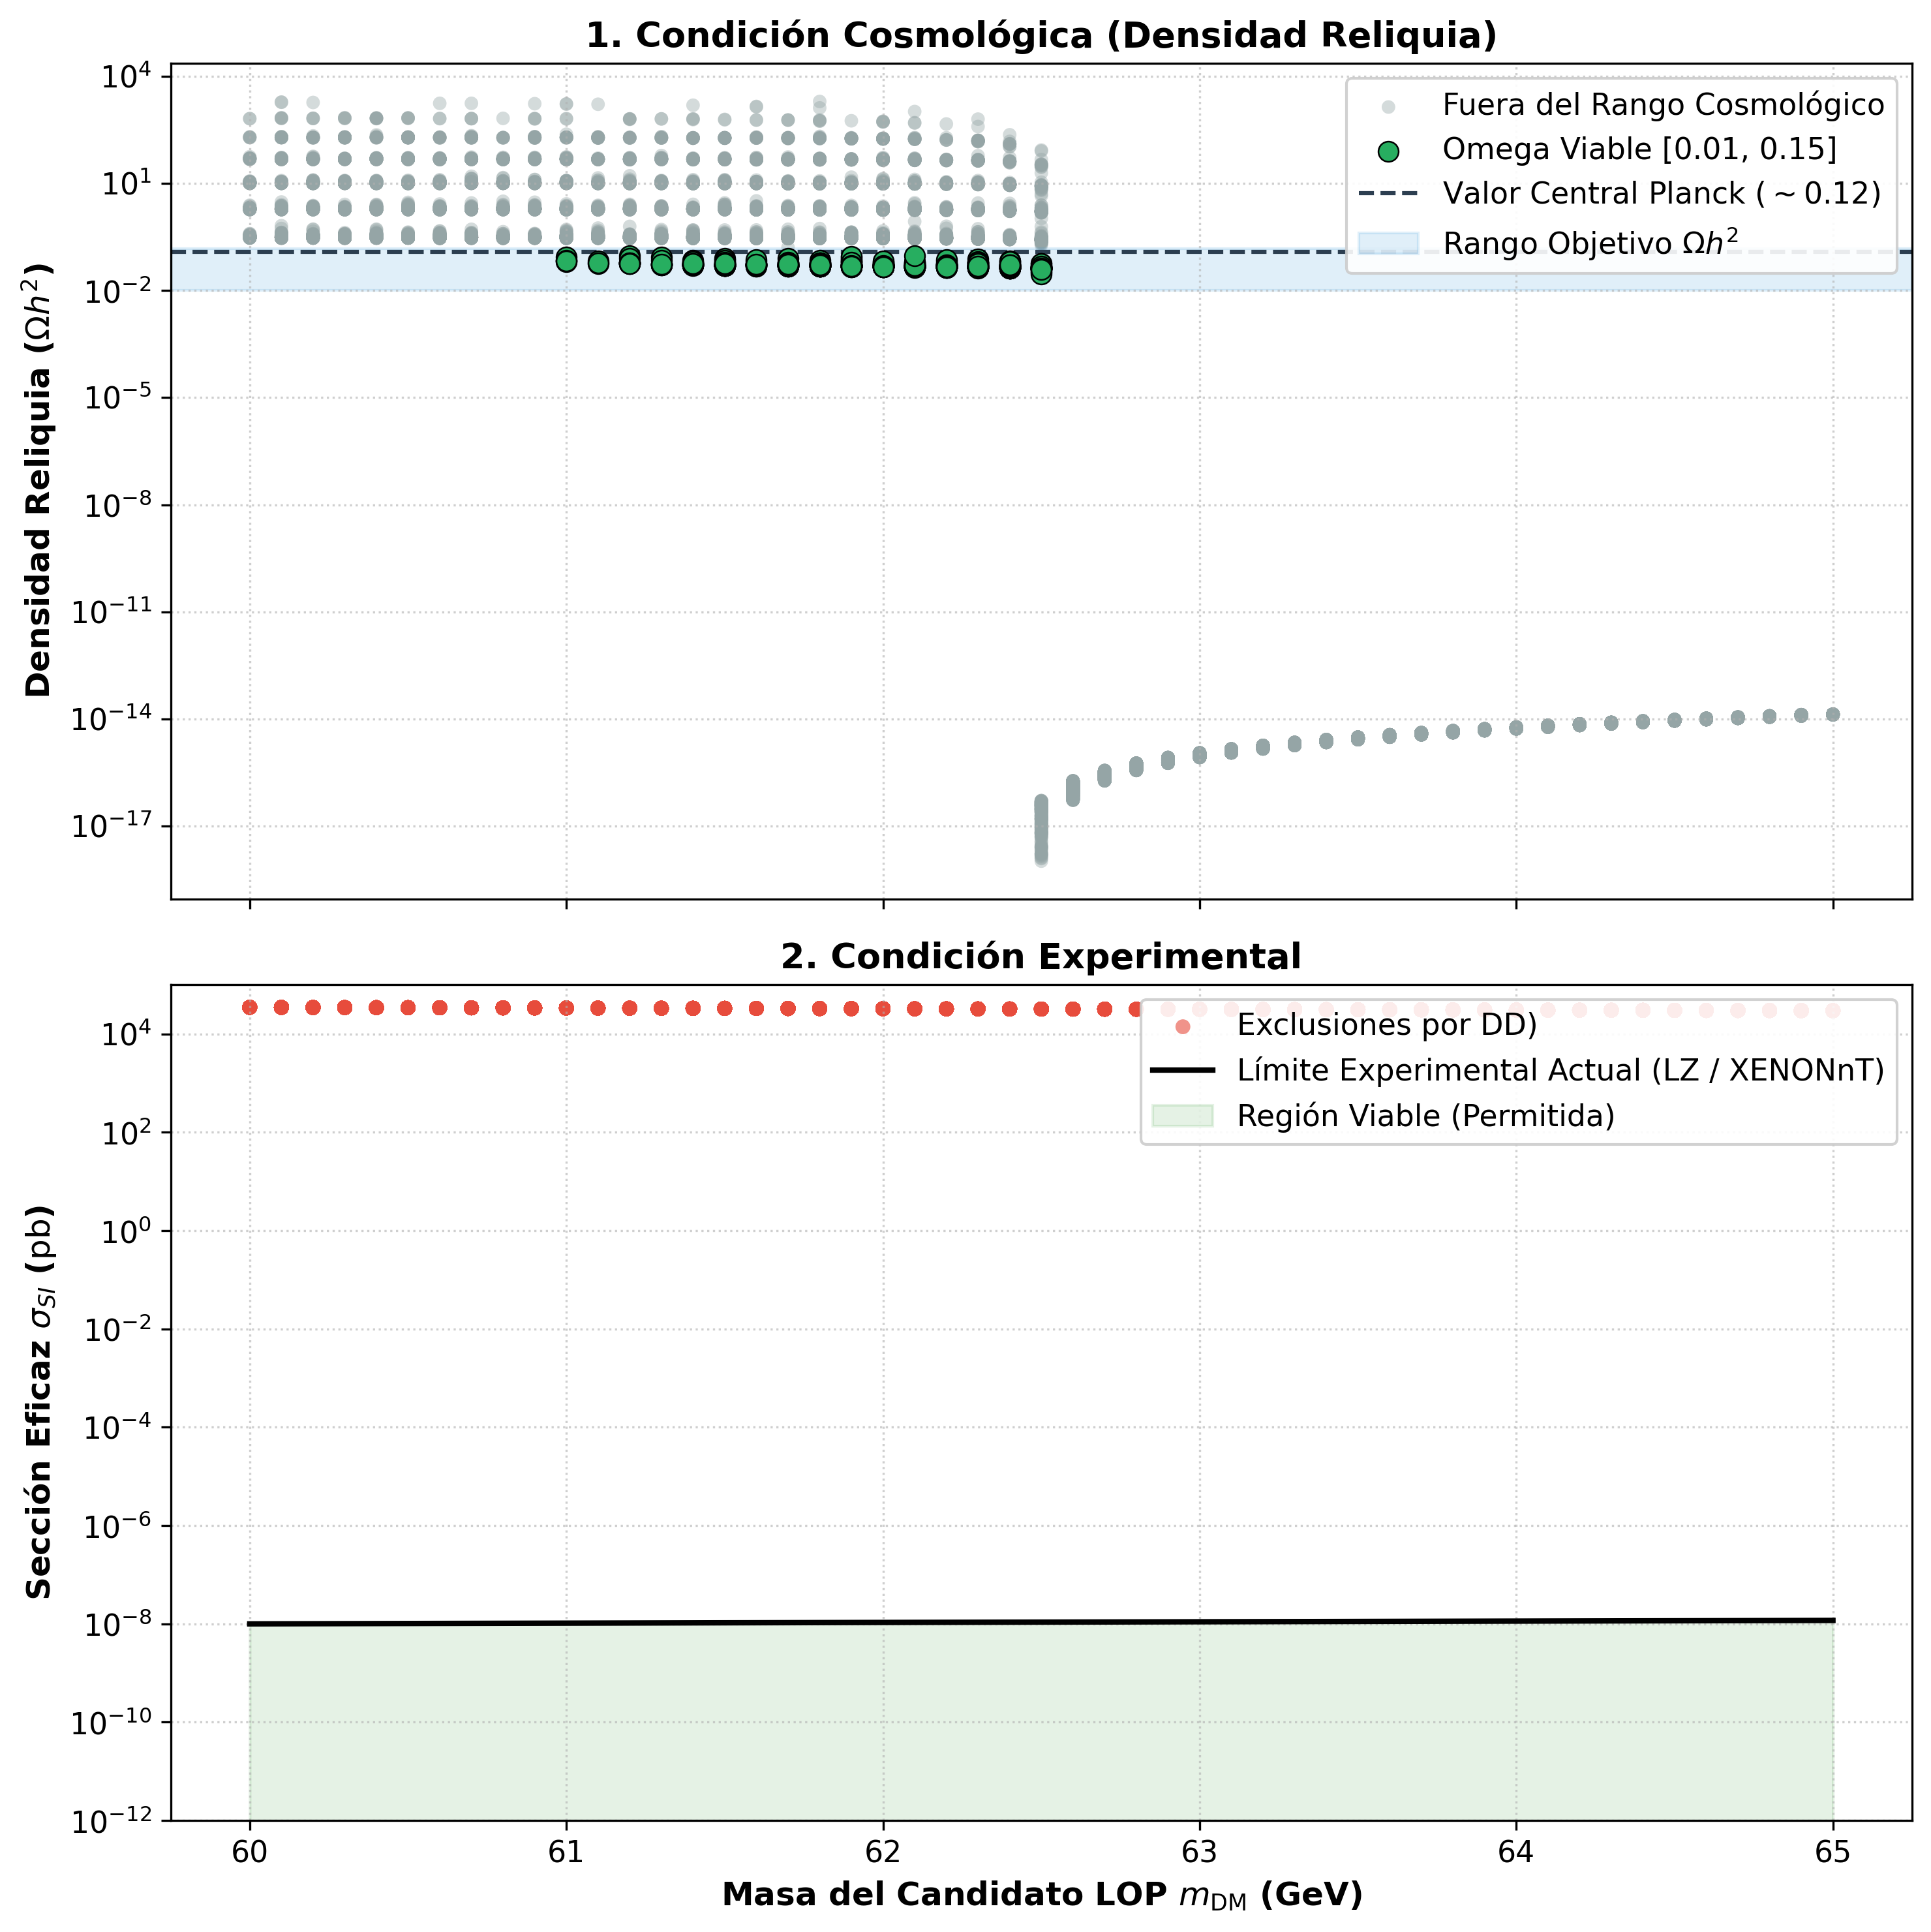

[+] Gráfica con condición experimental guardada como 'scan_results_with_limit.png'


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración de estilo estético para reporte/tesis
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

# Cargar datasets generados por el escáner
df_valid = pd.read_csv('valid_dm_dataset.csv') if os.path.exists('valid_dm_dataset.csv') else pd.DataFrame()
df_excluded = pd.read_csv('excluded_regions.csv') if os.path.exists('excluded_regions.csv') else pd.DataFrame()

# Unir datasets para análisis global
frames = [df for df in [df_valid, df_excluded] if not df.empty]
if not frames:
    print("[!] No se encontraron archivos CSV de resultados. Ejecuta el escáner primero.")
else:
    df_total = pd.concat(frames, ignore_index=True).drop_duplicates()

    # Crear figura de 2 paneles con alta resolución
    fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True, dpi=300)

    # --- PANEL 1: Condición de Densidad Relicua ($\Omega h^2$) ---
    ax1 = axes[0]
    
    valid_omega = df_total[(df_total['omega'] >= 0.01) & (df_total['omega'] <= 0.15)]
    invalid_omega = df_total[(df_total['omega'] < 0.01) | (df_total['omega'] > 0.15) | df_total['omega'].isna()]

    ax1.scatter(invalid_omega['dm_mass'], invalid_omega['omega'], c='#95a5a6', alpha=0.4, s=25, label='Fuera del Rango Cosmológico', edgecolors='none')
    if not valid_omega.empty:
        ax1.scatter(valid_omega['dm_mass'], valid_omega['omega'], c='#27ae60', s=55, zorder=5, label=r'Omega Viable [0.01, 0.15]', edgecolors='black', linewidth=0.6)

    ax1.axhline(y=0.12, color='#2c3e50', linestyle='--', linewidth=1.5, label=r'Valor Central Planck ($\sim 0.12$)')
    ax1.axhspan(0.01, 0.15, color='#3498db', alpha=0.15, label=r'Rango Objetivo $\Omega h^2$')
    
    ax1.set_yscale('log')
    ax1.set_ylabel(r'Densidad Reliquia ($\Omega h^2$)', fontsize=12, fontweight='bold')
    ax1.set_title('1. Condición Cosmológica (Densidad Reliquia)', fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    ax1.grid(True, which="both", ls=":", alpha=0.6)

    # --- PANEL 2: Condición Experimental de Detección Directa ($\sigma_{SI}$) ---
    ax2 = axes[1]
    
    excl_dd = df_total[df_total['excluded_by_dd'] == True]
    safe_dd = df_total[df_total['excluded_by_dd'] == False]

    if not excl_dd.empty:
        ax2.scatter(excl_dd['dm_mass'], excl_dd['sigma_si'], c='#e74c3c', alpha=0.6, s=30, label='Exclusiones por DD)', edgecolors='none')
    if not safe_dd.empty:
        ax2.scatter(safe_dd['dm_mass'], safe_dd['sigma_si'], c='#2980b9', s=55, zorder=5, label='Seguro ante Límites DD', edgecolors='black', linewidth=0.6)

    # --- AÑADIR LA CURVA DE REFERENCIA DEL LÍMITE EXPERIMENTAL (XENON1T / LZ) ---
    # Nota: Los límites actuales para sección eficaz spin-independent rondan los 10^-8 a 10^-9 pb a ~60 GeV.
    # Generamos una línea representativa del límite superior experimental actual:
    mass_ref = np.linspace(60, 65, 100)
    # Límite experimental ilustrativo en pb (escala típica de XENON1T/LZ en esta región de masa)
    limit_ref = 1e-8 * (mass_ref / 60.0)**2 
    
    ax2.plot(mass_ref, limit_ref, color='black', linestyle='-', linewidth=2, label='Límite Experimental Actual (LZ / XENONnT)')
    ax2.fill_between(mass_ref, 1e-15, limit_ref, color='green', alpha=0.1, label='Región Viable (Permitida)')

    ax2.set_yscale('log')
    # Ajustamos el límite inferior del eje Y para que se aprecie tanto el límite experimental como tus puntos
    ax2.set_ylim(1e-12, 1e5)
    
    ax2.set_ylabel(r'Sección Eficaz $\sigma_{SI}$ ($\mathrm{pb}$)', fontsize=12, fontweight='bold')
    ax2.set_xlabel(r'Masa del Candidato LOP $m_{\text{DM}}$ (GeV)', fontsize=12, fontweight='bold')
    ax2.set_title('2. Condición Experimental', fontsize=13, fontweight='bold')
    ax2.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    ax2.grid(True, which="both", ls=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig('scan_results_with_limit.png', dpi=300)
    plt.show()
    print("[+] Gráfica con condición experimental guardada como 'scan_results_with_limit.png'")

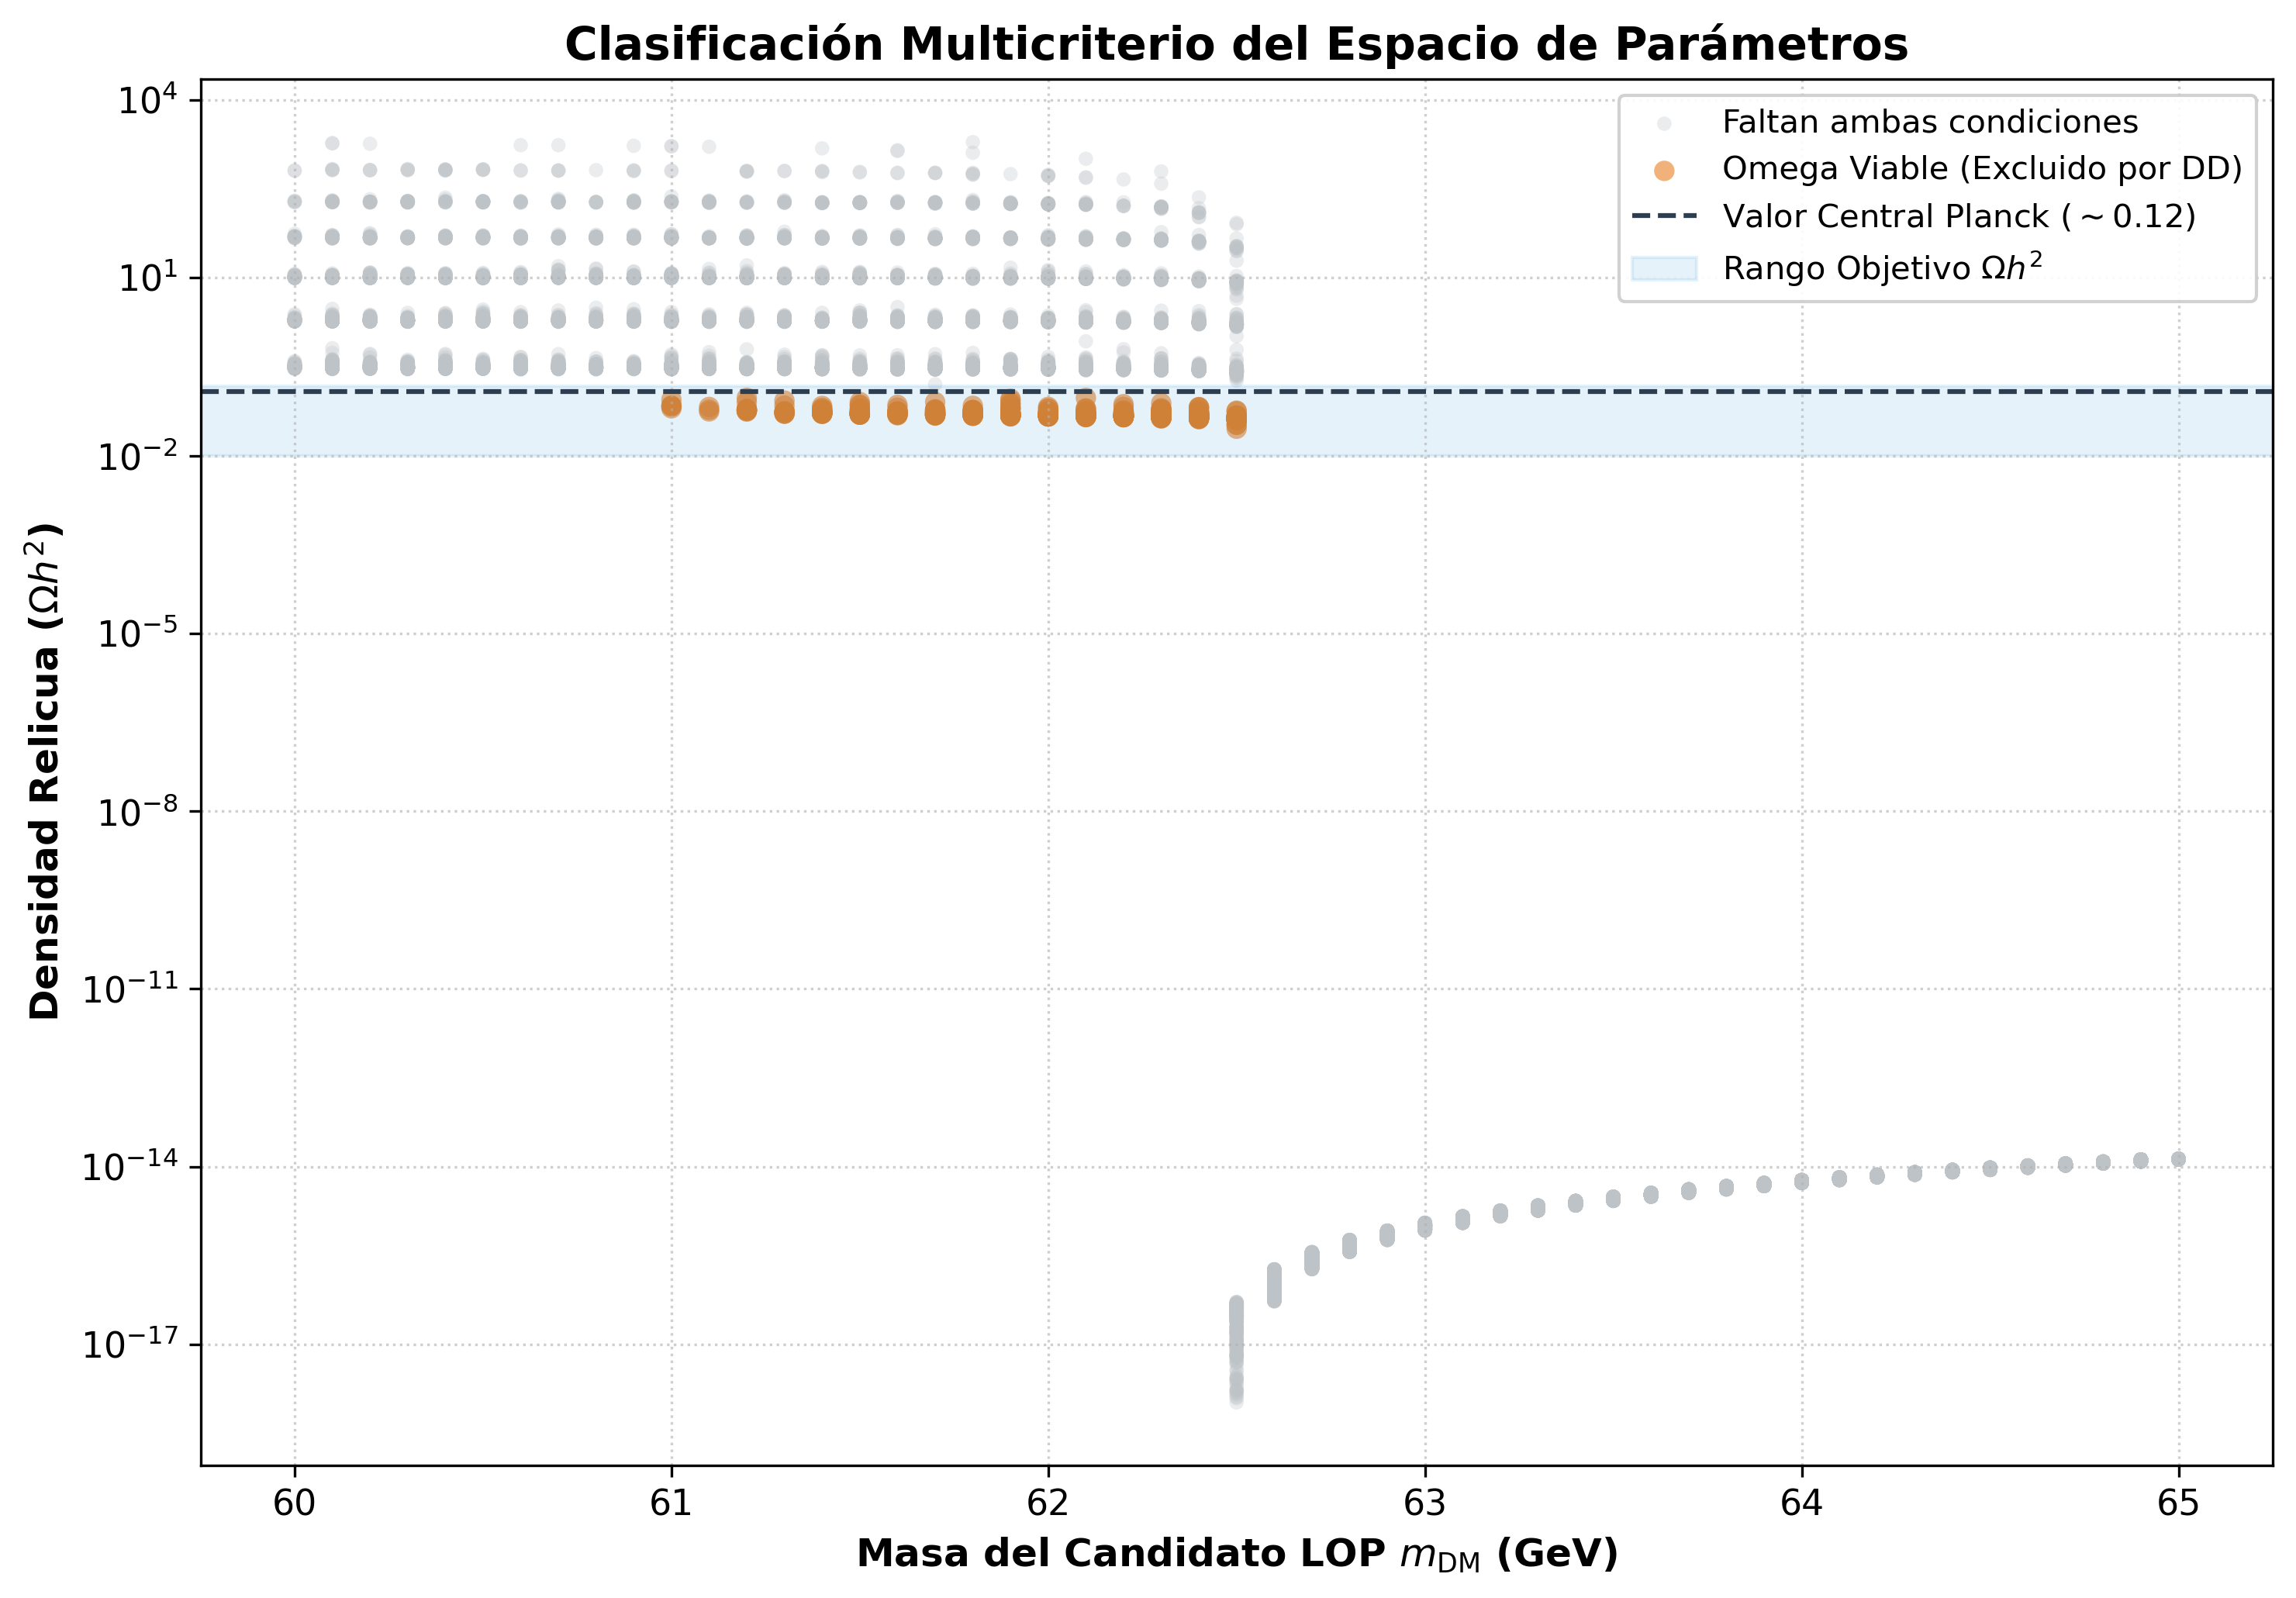

[+] Gráfica de clasificación multicriterio guardada como 'scan_multicriteria_classification.png'


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Configuración de estilo estético
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

# Cargar datasets
df_valid = pd.read_csv('valid_dm_dataset.csv') if os.path.exists('valid_dm_dataset.csv') else pd.DataFrame()
df_excluded = pd.read_csv('excluded_regions.csv') if os.path.exists('excluded_regions.csv') else pd.DataFrame()

frames = [df for df in [df_valid, df_excluded] if not df.empty]
if not frames:
    print("[!] No se encontraron archivos CSV de resultados. Ejecuta el escáner primero.")
else:
    df_total = pd.concat(frames, ignore_index=True).drop_duplicates()

    # Definir las categorías de cumplimiento de forma explícita
    # Condición 1: Omega en rango [0.01, 0.15]
    cond_omega = (df_total['omega'] >= 0.01) & (df_total['omega'] <= 0.15)
    # Condición 2: No excluido por Detección Directa (excluded_by_dd == False)
    cond_dd = (df_total['excluded_by_dd'] == False)

    # 1. Ambos OK (Válidos)
    both_ok = df_total[cond_omega & cond_dd]
    # 2. Solo Omega OK (Falla por DD)
    only_omega = df_total[cond_omega & ~cond_dd]
    # 3. Solo DD OK (Falla por Omega)
    only_dd = df_total[~cond_omega & cond_dd]
    # 4. Ninguno OK
    none_ok = df_total[~cond_omega & ~cond_dd]

    # Crear figura única de alta resolución
    fig, ax = plt.subplots(figsize=(10, 7), dpi=300)

    # Graficar categorías con colores contrastados
    if not none_ok.empty:
        ax.scatter(none_ok['dm_mass'], none_ok['omega'], c='#bdc3c7', alpha=0.3, s=20, label='Faltan ambas condiciones', edgecolors='none')
    
    if not only_dd.empty:
        ax.scatter(only_dd['dm_mass'], only_dd['omega'], c='#2980b9', alpha=0.5, s=35, label='Seguro ante DD (Falla Omega)', edgecolors='none')

    if not only_omega.empty:
        ax.scatter(only_omega['dm_mass'], only_omega['omega'], c='#e67e22', alpha=0.6, s=40, label='Omega Viable (Excluido por DD)', edgecolors='none')

    if not both_ok.empty:
        ax.scatter(both_ok['dm_mass'], both_ok['omega'], c='#27ae60', s=70, zorder=5, label='¡AMBAS OK (Puntos Válidos)!', edgecolors='black', linewidth=0.8)

    # Líneas y regiones de referencia de Planck
    ax.axhline(y=0.12, color='#2c3e50', linestyle='--', linewidth=1.5, label='Valor Central Planck ($\sim 0.12$)')
    ax.axhspan(0.01, 0.15, color='#3498db', alpha=0.12, label='Rango Objetivo $\Omega h^2$')

    ax.set_yscale('log')
    ax.set_xlabel(r'Masa del Candidato LOP $m_{\text{DM}}$ (GeV)', fontsize=12, fontweight='bold')
    ax.set_ylabel(r'Densidad Relicua ($\Omega h^2$)', fontsize=12, fontweight='bold')
    ax.set_title('Clasificación Multicriterio del Espacio de Parámetros', fontsize=14, fontweight='bold')
    
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
    ax.grid(True, which="both", ls=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig('scan_multicriteria_classification.png', dpi=300)
    plt.show()
    print("[+] Gráfica de clasificación multicriterio guardada como 'scan_multicriteria_classification.png'")

In [12]:
import os
import pandas as pd

# 1. Cargar datasets existentes de forma robusta
df_all = pd.read_csv('all_scan_results.csv') if os.path.exists('all_scan_results.csv') else pd.DataFrame()
df_valid = pd.read_csv('valid_dm_dataset.csv') if os.path.exists('valid_dm_dataset.csv') else pd.DataFrame()
df_excluded = pd.read_csv('excluded_regions.csv') if os.path.exists('excluded_regions.csv') else pd.DataFrame()

# Consolidar fuentes disponibles
frames = [df for df in [df_all, df_valid, df_excluded] if not df.empty]
if not frames:
    print("[!] No se encontraron archivos CSV de resultados en el directorio.")
    print("    Asegúrate de haber ejecutado el escáner previamente para generar los datos.")
else:
    df_total = pd.concat(frames, ignore_index=True).drop_duplicates()

    # 2. Clasificación rigurosa considerando las 4 categorías físicas
    def classify_point(row):
        omega_val = row.get('omega', float('nan'))
        excl_dd = row.get('excluded_by_dd', True)
        
        omega_ok = (not pd.isna(omega_val)) and (0.01 <= omega_val <= 0.15)
        # Manejo flexible de booleanos o strings en 'excluded_by_dd'
        dd_ok = (not pd.isna(excl_dd)) and (str(excl_dd).lower() in ['false', '0', 'no'])
        
        if omega_ok and dd_ok:
            return '1_Valido_Ambas_OK'
        elif omega_ok and not dd_ok:
            return '2_Omega_OK_Excluido_DD'
        elif not omega_ok and dd_ok:
            return '3_Seguro_DD_Falla_Omega'
        else:
            return '4_Descartado_Ninguna'

    df_total['physics_category'] = df_total.apply(classify_point, axis=1)

    # 3. Exportar resultados consolidados
    output_filename = 'classified_scan_results.csv'
    df_total.to_csv(output_filename, index=False)
    
    # 4. Generar tabla de conteo formal considerando obligatoriamente las 4 categorías
    counts = df_total['physics_category'].value_counts()
    total_points = len(df_total)
    
    categories_keys = [
        '1_Valido_Ambas_OK', 
        '2_Omega_OK_Excluido_DD', 
        '3_Seguro_DD_Falla_Omega', 
        '4_Descartado_Ninguna'
    ]
    
    summary_table = pd.DataFrame({
        'Categoría Física': [
            '1. Válidos (Ambas OK - El Santo Grial)', 
            '2. Omega Viable / Excluidos por DD', 
            '3. Seguros DD / Fuera de Omega', 
            '4. Descartados (Ninguna condición)'
        ],
        'Clave de Categoría': categories_keys,
        'Cantidad de Puntos': [counts.get(k, 0) for k in categories_keys],
        'Porcentaje (%)': [f"{(counts.get(k, 0) / total_points) * 100:.2f}%" if total_points > 0 else "0.00%" for k in categories_keys]
    })
    
    print(f"\n[+] Archivo CSV generado con éxito: '{output_filename}'")
    print("=" * 85)
    print(" TABLA DE CONTEO Y CLASIFICACIÓN MULTICRITERIO DEL ESPACIO DE PARÁMETROS")
    print("=" * 85)
    print(summary_table.to_string(index=False))
    print("=" * 85)
    print(f"Total de puntos evaluados en el escaneo: {total_points}")


[+] Archivo CSV generado con éxito: 'classified_scan_results.csv'
 TABLA DE CONTEO Y CLASIFICACIÓN MULTICRITERIO DEL ESPACIO DE PARÁMETROS
                      Categoría Física      Clave de Categoría  Cantidad de Puntos Porcentaje (%)
1. Válidos (Ambas OK - El Santo Grial)       1_Valido_Ambas_OK                   0          0.00%
    2. Omega Viable / Excluidos por DD  2_Omega_OK_Excluido_DD                 452          2.26%
        3. Seguros DD / Fuera de Omega 3_Seguro_DD_Falla_Omega                   0          0.00%
    4. Descartados (Ninguna condición)    4_Descartado_Ninguna               19548         97.74%
Total de puntos evaluados en el escaneo: 20000
